In [ ]:
from google.colab import drive #USE YOUR GOOGLE DRIVE
drive.mount('/content/drive')

# Re-unzip dataset fresh each session (since /content/ wipes on disconnect)
!unzip -q "/content/drive/MyDrive/Wall_Crack_Dataset.zip" -d /content/dataset

import torch
print("Using device:", "cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

root = "/content/dataset/Crack_Hole_Normal_Dataset"
data_yaml_path = f"{root}/data.yaml"
project_dir = "/content/drive/MyDrive/wall_crack_runs"
your_name = "emmanuel"  # <-- change this to your own name, each teammate does the same with their own name
results_log_path = f"/content/drive/MyDrive/wall_crack_results_{your_name}.json"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/dataset/Crack_Hole_Normal_Dataset/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/dataset/Crack_Hole_Normal_Dataset/images/postmodeltest/5389971669.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/dataset/Crack_Hole_Normal_Dataset/images/postmodeltest/5390137839.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/dataset/Crack_Hole_Normal_Dataset/images/postmodeltest/5393872940.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/dataset/Crack_Hole_Normal_Dataset/images/postmodeltest/5394003978.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/dataset/Crack_Hole_Normal_Dataset/images/postmodeltest/5412298382.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/dataset/Crack_Hole_Normal_Dataset/images/postmodeltest/5414071894.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
r

In [ ]:
import os, random, shutil #run this once

img_train_dir = f"{root}/images/train"
lbl_train_dir = f"{root}/labels/train"
img_val_dir = f"{root}/images/val"
lbl_val_dir = f"{root}/labels/val"

if os.path.exists(img_val_dir) and len(os.listdir(img_val_dir)) > 0:
    print("Val split already exists this session, skipping.")
    print("Train images:", len(os.listdir(img_train_dir)))
    print("Val images:", len(os.listdir(img_val_dir)))
else:
    os.makedirs(img_val_dir, exist_ok=True)
    os.makedirs(lbl_val_dir, exist_ok=True)

    all_imgs = sorted([f for f in os.listdir(img_train_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    random.seed(42)
    random.shuffle(all_imgs)

    val_fraction = 0.15
    n_val = int(len(all_imgs) * val_fraction)
    val_imgs = all_imgs[:n_val]

    print(f"Total train pool: {len(all_imgs)} | Moving {len(val_imgs)} to val (15%)")

    for img_name in val_imgs:
        label_name = os.path.splitext(img_name)[0] + ".txt"
        shutil.move(os.path.join(img_train_dir, img_name), os.path.join(img_val_dir, img_name))
        src_label = os.path.join(lbl_train_dir, label_name)
        if os.path.exists(src_label):
            shutil.move(src_label, os.path.join(lbl_val_dir, label_name))

    print("Remaining train images:", len(os.listdir(img_train_dir)))
    print("Val images:", len(os.listdir(img_val_dir)))

# Write/refresh data.yaml regardless
with open(data_yaml_path, "w") as f:
    f.write(f"path: {root}\n")
    f.write("train: images/train\n")
    f.write("val: images/val\n")
    f.write("test: images/test\n")
    f.write("nc: 3\n")
    f.write("names:\n")
    f.write("  0: normal\n")
    f.write("  1: crack\n")
    f.write("  2: hole\n")

print("\ndata.yaml contents:")
print(open(data_yaml_path).read())

Val split already exists this session, skipping.
Train images: 1600
Val images: 240

data.yaml contents:
path: /content/dataset/Crack_Hole_Normal_Dataset
train: images/train
val: images/val
test: images/test
nc: 3
names:
  0: normal
  1: crack
  2: hole



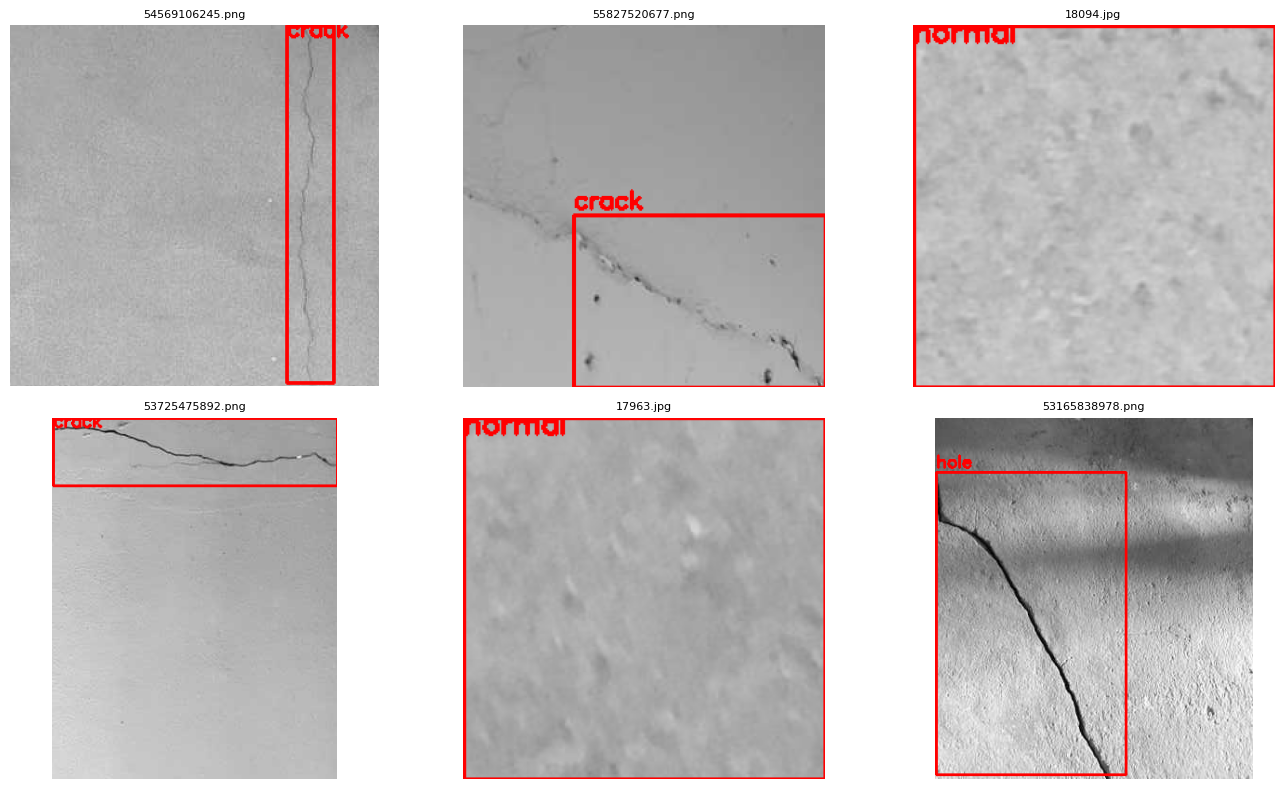

In [ ]:
#visualise data (part3)
import cv2
import matplotlib.pyplot as plt
import os
import random
root = "/content/dataset/Crack_Hole_Normal_Dataset"

def draw_yolo_boxes(img_path, label_path, class_names):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f.readlines():
                cls_id, xc, yc, bw, bh = map(float, line.strip().split())
                cls_id = int(cls_id)
                x1 = int((xc - bw/2) * w)
                y1 = int((yc - bh/2) * h)
                x2 = int((xc + bw/2) * w)
                y2 = int((yc + bh/2) * h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(img, class_names[cls_id], (x1, max(y1-5, 10)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    return img

class_names = ["normal", "crack", "hole"]
img_dir = f"{root}/images/train"
lbl_dir = f"{root}/labels/train"

# Add a check for the directory's existence
if not os.path.exists(img_dir):
    raise FileNotFoundError(
        f"The image directory '{img_dir}' was not found. "
        "Please ensure the dataset has been correctly unzipped and "
        "the data splitting cells have been run successfully. "
        "You may need to re-run the notebook from the beginning."
    )

sample_files = random.sample(os.listdir(img_dir), 6)

plt.figure(figsize=(14, 8))
for i, fname in enumerate(sample_files):
    img_path = os.path.join(img_dir, fname)
    label_path = os.path.join(lbl_dir, os.path.splitext(fname)[0] + ".txt")
    img = draw_yolo_boxes(img_path, label_path, class_names)
    plt.subplot(2, 3, i+1)
    plt.imshow(img)
    plt.title(fname, fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
#model 1 *IMPORTANT* RUN ONLY YOURS, IT IS SAVED AFTER RUNNING

from ultralytics import YOLO
import torch, json, os

yolo_device = 0 if torch.cuda.is_available() else "cpu"
print(f"Using device: {yolo_device}")

data_yaml_path = f"{root}/data.yaml"
project_dir = "/content/drive/MyDrive/wall_crack_runs"
results_log_path = "/content/drive/MyDrive/wall_crack_results.json"

# Load existing log if present, else start fresh
if os.path.exists(results_log_path):
    with open(results_log_path) as f:
        results_log = json.load(f)
else:
    results_log = {}

# ---- Model 1: Baseline (Nano, 640, standard augments) ----
model_1 = YOLO("yolov8n.pt")

results_1 = model_1.train(
    data=data_yaml_path,
    imgsz=640,
    epochs=25,
    batch=16,
    device=yolo_device,
    project=project_dir,
    name="model1_baseline_n640",
    verbose=True,
)

# ---- Validate + log immediately after training ----
metrics_1 = model_1.val(data=data_yaml_path, split="val", device=yolo_device)

results_log["model_1_baseline"] = {
    "weights": "yolov8n.pt",
    "imgsz": 640,
    "epochs": 25,
    "augmentation": "standard",
    "mAP50": float(metrics_1.box.map50),
    "mAP50-95": float(metrics_1.box.map),
    "precision": float(metrics_1.box.mp),
    "recall": float(metrics_1.box.mr),
}

with open(results_log_path, "w") as f:
    json.dump(results_log, f, indent=2)

print(results_log["model_1_baseline"])

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
#model 2 (just change epoch to 50)
#model 2 *IMPORTANT* RUN ONLY YOURS, IT IS SAVED AFTER RUNNING

from ultralytics import YOLO
import torch, json, os

yolo_device = 0 if torch.cuda.is_available() else "cpu"
print(f"Using device: {yolo_device}")

data_yaml_path = f"{root}/data.yaml"
project_dir = "/content/drive/MyDrive/wall_crack_runs"
results_log_path = "/content/drive/MyDrive/wall_crack_results.json"

if os.path.exists(results_log_path):
    with open(results_log_path) as f:
        results_log = json.load(f)
else:
    results_log = {}

# ---- Model 2: Nano, more epochs (50) ----
model_2 = YOLO("yolov8n.pt")

results_2 = model_2.train(
    data=data_yaml_path,
    imgsz=640,
    epochs=50,
    batch=16,
    device=yolo_device,
    project=project_dir,
    name="model2_more_epochs_n640",
    verbose=True,
)

metrics_2 = model_2.val(data=data_yaml_path, split="val", device=yolo_device)

results_log["model_2_more_epochs"] = {
    "weights": "yolov8n.pt",
    "imgsz": 640,
    "epochs": 50,
    "augmentation": "standard",
    "mAP50": float(metrics_2.box.map50),
    "mAP50-95": float(metrics_2.box.map),
    "precision": float(metrics_2.box.mp),
    "recall": float(metrics_2.box.mr),
}

with open(results_log_path, "w") as f:
    json.dump(results_log, f, indent=2)

print(results_log["model_2_more_epochs"])

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
#model 3 (i forgot)
#model 3 *IMPORTANT* RUN ONLY YOURS, IT IS SAVED AFTER RUNNING
!pip install ultralytics
from ultralytics import YOLO
import torch, json, os

yolo_device = 0 if torch.cuda.is_available() else "cpu"
print(f"Using device: {yolo_device}")

data_yaml_path = f"{root}/data.yaml"
project_dir = "/content/drive/MyDrive/wall_crack_runs"
results_log_path = "/content/drive/MyDrive/wall_crack_results.json"

if os.path.exists(results_log_path):
    with open(results_log_path) as f:
        results_log = json.load(f)
else:
    results_log = {}

# ---- Model 3: Small, same epochs as baseline (25) ----
model_3 = YOLO("yolov8s.pt")

results_3 = model_3.train(
    data=data_yaml_path,
    imgsz=640,
    epochs=25,
    batch=16,
    device=yolo_device,
    project=project_dir,
    name="model3_small_s640",
    verbose=True,
)

metrics_3 = model_3.val(data=data_yaml_path, split="val", device=yolo_device)

results_log["model_3_small"] = {
    "weights": "yolov8s.pt",
    "imgsz": 640,
    "epochs": 25,
    "augmentation": "standard",
    "mAP50": float(metrics_3.box.map50),
    "mAP50-95": float(metrics_3.box.map),
    "precision": float(metrics_3.box.mp),
    "recall": float(metrics_3.box.mr),
}

with open(results_log_path, "w") as f:
    json.dump(results_log, f, indent=2)

print(results_log["model_3_small"])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Using device: 0
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/Crack_Hole_Normal_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, df

In [ ]:
from ultralytics import YOLO
model = YOLO("/content/drive/MyDrive/facade_detection/model3_yolov8s/weights/best.pt")
metrics_3 = model.val(data="path/to/data.yaml")  # re-run validation only, seconds not hours
print(metrics_3.box.map50, metrics_3.box.map, metrics_3.box.mp, metrics_3.box.mr)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/facade_detection/model3_yolov8s/weights/best.pt'

In [ ]:
#model 4
#model 4 *IMPORTANT* RUN ONLY YOURS, IT IS SAVED AFTER RUNNING

from ultralytics import YOLO
import torch, json, os

yolo_device = 0 if torch.cuda.is_available() else "cpu"
print(f"Using device: {yolo_device}")

data_yaml_path = f"{root}/data.yaml"
project_dir = "/content/drive/MyDrive/wall_crack_runs"
results_log_path = "/content/drive/MyDrive/wall_crack_results.json"

if os.path.exists(results_log_path):
    with open(results_log_path) as f:
        results_log = json.load(f)
else:
    results_log = {}

# ---- Model 4: Medium, same epochs as baseline (25) ----
# NOTE: batch lowered to 8 — Medium is bigger and more likely to hit CUDA out-of-memory
# on a free T4 at batch=16. If it still OOMs, drop to batch=4.
model_4 = YOLO("yolov8m.pt")

results_4 = model_4.train(
    data=data_yaml_path,
    imgsz=640,
    epochs=25,
    batch=8,
    device=yolo_device,
    project=project_dir,
    name="model4_medium_m640",
    verbose=True,
)

metrics_4 = model_4.val(data=data_yaml_path, split="val", device=yolo_device)

results_log["model_4_medium"] = {
    "weights": "yolov8m.pt",
    "imgsz": 640,
    "epochs": 25,
    "augmentation": "standard",
    "mAP50": float(metrics_4.box.map50),
    "mAP50-95": float(metrics_4.box.map),
    "precision": float(metrics_4.box.mp),
    "recall": float(metrics_4.box.mr),
}

with open(results_log_path, "w") as f:
    json.dump(results_log, f, indent=2)

print(results_log["model_4_medium"])

In [ ]:
#model 5
#model 5 *IMPORTANT* RUN ONLY YOURS, IT IS SAVED AFTER RUNNING

from ultralytics import YOLO
import torch, json, os

yolo_device = 0 if torch.cuda.is_available() else "cpu"
print(f"Using device: {yolo_device}")

data_yaml_path = f"{root}/data.yaml"
project_dir = "/content/drive/MyDrive/wall_crack_runs"
results_log_path = "/content/drive/MyDrive/wall_crack_results.json"

if os.path.exists(results_log_path):
    with open(results_log_path) as f:
        results_log = json.load(f)
else:
    results_log = {}

# ---- Model 5: Nano, lower resolution (416) ----
model_5 = YOLO("yolov8n.pt")

results_5 = model_5.train(
    data=data_yaml_path,
    imgsz=416,
    epochs=25,
    batch=16,
    device=yolo_device,
    project=project_dir,
    name="model5_res416_n416",
    verbose=True,
)

# NOTE: imgsz=416 must be passed here too, or validation runs at the wrong resolution
metrics_5 = model_5.val(data=data_yaml_path, split="val", imgsz=416, device=yolo_device)

results_log["model_5_low_res"] = {
    "weights": "yolov8n.pt",
    "imgsz": 416,
    "epochs": 25,
    "augmentation": "standard",
    "mAP50": float(metrics_5.box.map50),
    "mAP50-95": float(metrics_5.box.map),
    "precision": float(metrics_5.box.mp),
    "recall": float(metrics_5.box.mr),
}

with open(results_log_path, "w") as f:
    json.dump(results_log, f, indent=2)

print(results_log["model_5_low_res"])

In [ ]:
#Model 6 (special, need to add augmentations)
#model 6 *IMPORTANT* RUN ONLY YOURS, IT IS SAVED AFTER RUNNING

from ultralytics import YOLO
import torch, json, os

yolo_device = 0 if torch.cuda.is_available() else "cpu"
print(f"Using device: {yolo_device}")

data_yaml_path = f"{root}/data.yaml"
project_dir = "/content/drive/MyDrive/wall_crack_runs"
results_log_path = "/content/drive/MyDrive/wall_crack_results.json"

if os.path.exists(results_log_path):
    with open(results_log_path) as f:
        results_log = json.load(f)
else:
    results_log = {}

# ---- Model 6: Nano, heavy augmentation ----
model_6 = YOLO("yolov8n.pt")

results_6 = model_6.train(
    data=data_yaml_path,
    imgsz=640,
    epochs=25,
    batch=16,
    device=yolo_device,
    project=project_dir,
    name="model6_heavy_aug_n640",
    verbose=True,
    hsv_h=0.03,
    hsv_s=0.9,
    hsv_v=0.6,
    degrees=15.0,
    translate=0.2,
    scale=0.9,
    shear=5.0,
    flipud=0.2,
    fliplr=0.5,
    mixup=0.15,
)

metrics_6 = model_6.val(data=data_yaml_path, split="val", device=yolo_device)

results_log["model_6_heavy_aug"] = {
    "weights": "yolov8n.pt",
    "imgsz": 640,
    "epochs": 25,
    "augmentation": "heavy",
    "mAP50": float(metrics_6.box.map50),
    "mAP50-95": float(metrics_6.box.map),
    "precision": float(metrics_6.box.mp),
    "recall": float(metrics_6.box.mr),
}

with open(results_log_path, "w") as f:
    json.dump(results_log, f, indent=2)

print(results_log["model_6_heavy_aug"])

In [ ]:
results_log = {
    "model_1_baseline": {
        "weights": "yolov8n.pt", "imgsz": 640, "epochs": 25, "augmentation": "standard",
        "mAP50": 0.6552602050389617, "mAP50-95": 0.4702375229011594,
        "precision": 0.6511189634643019, "recall": 0.6609208103130756
    },
    "model_2_more_epochs": {
        "weights": "yolov8n.pt", "imgsz": 640, "epochs": 50, "augmentation": "standard",
        "mAP50": 0.6787156436308344, "mAP50-95": 0.48817219507759807,
        "precision": 0.7170370323317966, "recall": 0.673423564915856
    },
    "model_3_small": {
        "weights": "yolov8s.pt", "imgsz": 640, "epochs": 25, "augmentation": "standard",
        "mAP50": 0.66623, "mAP50-95": 0.47897,
        "precision": 0.68749, "recall": 0.65057
    },
    "model_4_medium": {
        "weights": "yolov8m.pt", "imgsz": 640, "epochs": 25, "augmentation": "standard",
        "mAP50": 0.6276034924982644, "mAP50-95": 0.45002331615956415,
        "precision": 0.6555440854283962, "recall": 0.639963167587477
    },
    "model_5_low_res": {
        "weights": "yolov8n.pt", "imgsz": 416, "epochs": 25, "augmentation": "standard",
        "mAP50": 0.6579877739041453, "mAP50-95": 0.47977724105039116,
        "precision": 0.6767284261948392, "recall": 0.67619789320421
    },
    "model_6_heavy_aug": {
        "weights": "yolov8n.pt", "imgsz": 640, "epochs": 25, "augmentation": "heavy",
        "mAP50": 0.6169222571575382, "mAP50-95": 0.44506379023909987,
        "precision": 0.6400609122129397, "recall": 0.6457067235396803
    },
}

In [ ]:
import pandas as pd

trained_by = {
    'model_1_baseline': 'Masyitha',
    'model_2_more_epochs': 'Yanisa',
    'model_3_small': 'luc',
    'model_4_medium': 'KaiJie',
    'model_5_low_res': 'Emmanuel',
    'model_6_heavy_aug': 'Jeanett',
}

order = ['model_1_baseline', 'model_2_more_epochs', 'model_3_small',
         'model_4_medium', 'model_5_low_res', 'model_6_heavy_aug']

team_df = pd.DataFrame(results_log).T.loc[order]
team_df.insert(0, 'trained_by', [trained_by[m] for m in team_df.index])
team_df.index.name = 'Model'

# Round for cleaner display
team_df[['mAP50', 'mAP50-95', 'precision', 'recall']] = team_df[
    ['mAP50', 'mAP50-95', 'precision', 'recall']
].astype(float).round(3)

team_df

,trained_by,weights,imgsz,epochs,augmentation,mAP50,mAP50-95,precision,recall
Model,,,,,,,,,
model_1_baseline,Masyitha,yolov8n.pt,640,25,standard,0.655,0.470,0.651,0.661
model_2_more_epochs,Yanisa,yolov8n.pt,640,50,standard,0.679,0.488,0.717,0.673
model_3_small,luc,yolov8s.pt,640,25,standard,0.666,0.479,0.687,0.651
model_4_medium,KaiJie,yolov8m.pt,640,25,standard,0.628,0.450,0.656,0.640
model_5_low_res,Emmanuel,yolov8n.pt,416,25,standard,0.658,0.480,0.677,0.676
model_6_heavy_aug,Jeanett,yolov8n.pt,640,25,heavy,0.617,0.445,0.640,0.646


,trained_by,weights,imgsz,epochs,augmentation,mAP50,mAP50-95,precision,recall
model_name,,,,,,,,,
model_1_baseline,Masyitha,yolov8n.pt,640,25,standard,0.655,0.470,0.651,0.661
model_2_more_epochs,Yanisa,yolov8n.pt,640,50,standard,0.679,0.488,0.717,0.673
model_3_small,[teammate name],yolov8s.pt,640,25,standard,0.666,0.479,0.687,0.651
model_4_medium,KaiJie,yolov8m.pt,640,25,standard,0.628,0.450,0.656,0.640
model_5_low_res,Emmanuel,yolov8n.pt,416,25,standard,0.658,0.480,0.677,0.676
model_6_heavy_aug,Jeanett,yolov8n.pt,640,25,heavy,0.617,0.445,0.640,0.646


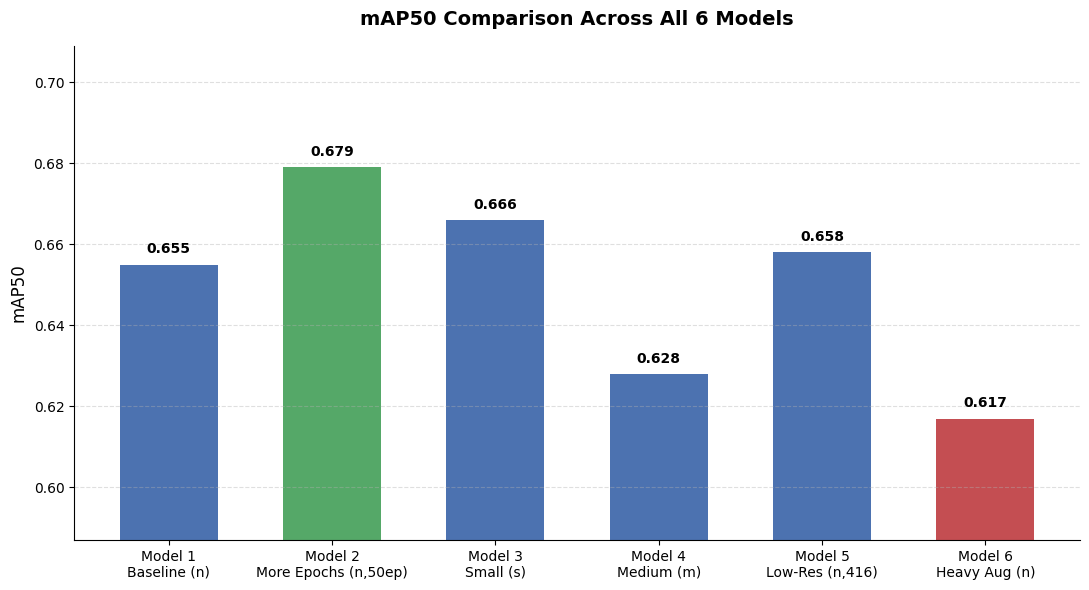

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ---- All 6 models, hardcoded so you don't need to upload/merge anything ----
results_log = {
    "model_1_baseline": {
        "weights": "yolov8n.pt", "imgsz": 640, "epochs": 25, "augmentation": "standard",
        "mAP50": 0.6552602050389617, "mAP50-95": 0.4702375229011594,
        "precision": 0.6511189634643019, "recall": 0.6609208103130756,
        "trained_by": "Masyitha"
    },
    "model_2_more_epochs": {
        "weights": "yolov8n.pt", "imgsz": 640, "epochs": 50, "augmentation": "standard",
        "mAP50": 0.6787156436308344, "mAP50-95": 0.48817219507759807,
        "precision": 0.7170370323317966, "recall": 0.673423564915856,
        "trained_by": "Yanisa"
    },
    "model_3_small": {
        "weights": "yolov8s.pt", "imgsz": 640, "epochs": 25, "augmentation": "standard",
        "mAP50": 0.66623, "mAP50-95": 0.47897,
        "precision": 0.68749, "recall": 0.65057,
        "trained_by": "[teammate name]"
    },
    "model_4_medium": {
        "weights": "yolov8m.pt", "imgsz": 640, "epochs": 25, "augmentation": "standard",
        "mAP50": 0.6276034924982644, "mAP50-95": 0.45002331615956415,
        "precision": 0.6555440854283962, "recall": 0.639963167587477,
        "trained_by": "KaiJie"
    },
    "model_5_low_res": {
        "weights": "yolov8n.pt", "imgsz": 416, "epochs": 25, "augmentation": "standard",
        "mAP50": 0.6579877739041453, "mAP50-95": 0.47977724105039116,
        "precision": 0.6767284261948392, "recall": 0.67619789320421,
        "trained_by": "Emmanuel"
    },
    "model_6_heavy_aug": {
        "weights": "yolov8n.pt", "imgsz": 640, "epochs": 25, "augmentation": "heavy",
        "mAP50": 0.6169222571575382, "mAP50-95": 0.44506379023909987,
        "precision": 0.6400609122129397, "recall": 0.6457067235396803,
        "trained_by": "Jeanett"
    },
}

# ---- Build the table ----
order = ['model_1_baseline', 'model_2_more_epochs', 'model_3_small',
         'model_4_medium', 'model_5_low_res', 'model_6_heavy_aug']

team_df = pd.DataFrame(results_log).T.loc[order]
team_df.index.name = "model_name"
team_df = team_df[["trained_by", "weights", "imgsz", "epochs", "augmentation",
                    "mAP50", "mAP50-95", "precision", "recall"]]
team_df[["mAP50", "mAP50-95", "precision", "recall"]] = team_df[
    ["mAP50", "mAP50-95", "precision", "recall"]
].astype(float).round(3)

display(team_df)

# ---- Build the chart ----
labels_pretty = {
    'model_1_baseline': 'Model 1\nBaseline (n)',
    'model_2_more_epochs': 'Model 2\nMore Epochs (n,50ep)',
    'model_3_small': 'Model 3\nSmall (s)',
    'model_4_medium': 'Model 4\nMedium (m)',
    'model_5_low_res': 'Model 5\nLow-Res (n,416)',
    'model_6_heavy_aug': 'Model 6\nHeavy Aug (n)',
}

x_labels = [labels_pretty[m] for m in team_df.index]
values = team_df["mAP50"].values

best_idx = values.argmax()
worst_idx = values.argmin()
colors = ['#4C72B0'] * len(values)
colors[best_idx] = '#55A868'
colors[worst_idx] = '#C44E52'

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(x_labels, values, color=colors, width=0.6)
ax.set_ylim(values.min() - 0.03, values.max() + 0.03)

for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel('mAP50', fontsize=12)
ax.set_title('mAP50 Comparison Across All 6 Models', fontsize=14, fontweight='bold', pad=15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()